# Final project group 17

For the final project we are required make a program to create a map 
to calibrate the cameras with images 0_calib

## Project goals

1. Calibrate the stereo camera system and rectify the input images.
2. Then, for each sequence, do the following:
i. Compute disparity maps and reconstruct the 3D structure of the scene from the rectified stereo
image pairs.
ii. Detect the Husky A200 robot in the scene by processing the input images.
iii. Track the Husky A200 robot over time in 2D and 3D, including estimating its position during
complete occlusions

### Story
At ASTA (Autonomous Systems Testing Arena), our robotics testing facility at DTU, our mobile robot,
Husky, has been assigned to transport tools and equipment between testing stations. However,
we suspect that Husky has been taking some rather unusual routes instead of going directly to its
destinations. Luckily, two cameras have been recording its movements around ASTA, and we have
obtained footage of four of its recent deliveries. Your task is to calibrate the cameras and develop a
perception system that tracks Husky’s movements and reconstructs its trajectory in 2D and 3D, even
when it temporarily disappears from view

### Initialization

In [2]:
# Initialization

# calibration board ~ 80mm x 80mm

import numpy as np
import cv2 as cv2
import glob
import matplotlib.pyplot as plt

### Load image paths
# calibration
left_img_calib = sorted(glob.glob('0_calib/left/*.png'))
right_img_calib = sorted(glob.glob('0_calib/right/*.png'))

# no obstacle
left_img_no_obs = sorted(glob.glob('1_no_obstacle/left/*.png'))
right_img_no_obs = sorted(glob.glob('1_no_obstacle/right/*.png'))

# obstacle
left_img_obs = sorted(glob.glob('2_obstacle/left/*.png'))
right_img_obs = sorted(glob.glob('2_obstacle/right/*.png'))

# curved bend
left_img_curve = sorted(glob.glob('3_curved_bend/left/*.png'))
right_img_curve = sorted(glob.glob('3_curved_bend/right/*.png'))

# circle
left_img_circle = sorted(glob.glob('4_circle/left/*.png'))
right_img_circle = sorted(glob.glob('4_circle/right/*.png'))

### Camera calibration

In [15]:
nb_vertical = 7
nb_horizontal = 5

#cv2.CALIB_CB_ADAPTIVE_THRESH 
#                    + cv2.CALIB_CB_NORMALIZE_IMAGE

board_size = (80, 80) # mm
# Prepare object points, like (0, 0, 0), (1, 0, 0), (2, 0, 0) ....,(6, 5, 0).
objp_left = np.zeros((nb_horizontal * nb_vertical, 3), np.float32)*80
objp_left[:, :2] = np.mgrid[0:nb_vertical, 0:nb_horizontal].T.reshape(-1, 2)

objp_right = np.zeros((nb_horizontal * nb_vertical, 3), np.float32)*80
objp_right[:, :2] = np.mgrid[0:nb_vertical, 0:nb_horizontal].T.reshape(-1, 2)

# Arrays to store object points and image points from all the images.
objpoints_left = []  # 3D point in real world space.
imgpoints_left = []  # 2D points in image plane.

objpoints_right = []  # 3D point in real world space.
imgpoints_right = []  # 2D points in image plane.

criteria = (cv2.TERM_CRITERIA_EPS + 
            cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

assert left_img_calib
assert right_img_calib

for i, fname in enumerate(left_img_calib):
    img_l = cv2.imread(fname)
    h, w = img_l.shape[:2]
    gray_l = cv2.cvtColor(img_l, cv2.COLOR_BGR2GRAY)
    # flag cv2.CALIB_CB_ADAPTIVE_THRESH 
    ret_l, corners_l = cv2.findChessboardCornersSB(
        gray_l, (nb_vertical, nb_horizontal), cv2.CALIB_CB_EXHAUSTIVE
    )

    img_r = cv2.imread(right_img_calib[i])
    gray_r = cv2.cvtColor(img_r, cv2.COLOR_BGR2GRAY)
    ret_r, corners_r = cv2.findChessboardCornersSB(
        gray_r, (nb_vertical, nb_horizontal), cv2.CALIB_CB_EXHAUSTIVE
    )

    # If found, add object points, image points (after refining them).
    if (ret_l & ret_r) == True:
        objpoints_left.append(objp_left)
        objpoints_right.append(objp_right)

        # first (15,15)
        #corners2 = cv2.cornerSubPix(
        #    gray, corners, (9, 9), (-1, -1), criteria)
        
        imgpoints_left.append(corners_l)
        imgpoints_right.append(corners_r)
        
        # Draw and display the corners.
        img_l = cv2.drawChessboardCorners(
            img_l, (nb_vertical, nb_horizontal), corners_l, ret_l
        )
        
        img_r = cv2.drawChessboardCorners(
            img_r, (nb_vertical, nb_horizontal), corners_r, ret_r
        )
        
        #cv2.imshow("img", img)
        cv2.imwrite('chessboard/left/img{}.jpg'.format(i), img_l)
        cv2.imwrite('chessboard/right/img{}.jpg'.format(i), img_r)
        cv2.waitKey(50)
        print('Found pair: {}'.format(i))

#assert right_img_calib

#for i, fname in enumerate(right_img_calib):
#    img = cv2.imread(fname)
#    h, w = img.shape[:2]
#    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
#    ret, corners = cv2.findChessboardCornersSB(
#        gray, (nb_vertical, nb_horizontal), cv2.CALIB_CB_EXHAUSTIVE
#    )

    # If found, add object points, image points (after refining them).
#    if ret == True:
#        objpoints_right.append(objp_right)
#
        #corners2 = cv2.cornerSubPix(
        #    gray, corners, (9, 9), (-1, -1), criteria)
        
#        imgpoints_right.append(corners)

        # Draw and display the corners.
#        img = cv2.drawChessboardCorners(
#            img, (nb_vertical, nb_horizontal), corners, ret
#        )
        #cv2.imshow("img", img)
#        cv2.imwrite('chessboard/right/img{}.jpg'.format(i), img)
#        cv2.waitKey(50)

cv2.destroyAllWindows()

Found pair: 1
Found pair: 4
Found pair: 5
Found pair: 6
Found pair: 7
Found pair: 8
Found pair: 9
Found pair: 10
Found pair: 11
Found pair: 12
Found pair: 13
Found pair: 14
Found pair: 15
Found pair: 16
Found pair: 17
Found pair: 18
Found pair: 25
Found pair: 26
Found pair: 27
Found pair: 28
Found pair: 29
Found pair: 30
Found pair: 34
Found pair: 35
Found pair: 36


In [34]:
img = cv2.imread(left_img_calib[0], 0)
h, w = img.shape[:2]

ret_left, mtx_left, dist_left, rvecs, tvecs = cv2.calibrateCamera(
    objpoints_left, imgpoints_left, img.shape[::-1], None, None)

newcameramtx_left, roi_left = cv2.getOptimalNewCameraMatrix(mtx_left, dist_left, (w, h), 0, (w, h))

ret_right, mtx_right, dist_right, rvecs, tvecs = cv2.calibrateCamera(
    objpoints_right, imgpoints_right, img.shape[::-1], None, None
)
newcameramtx_right, roi_right = cv2.getOptimalNewCameraMatrix(mtx_right, dist_right, (w, h), 0, (w, h))

In [35]:
print("New camera matrix left:")
print(newcameramtx_left)
print("New camera matrix right")
print(newcameramtx_right)

print("Camera matrix left:")
print(mtx_left)
print("Camera matrix right:")
print(mtx_right)

print("Distortion coefficients left:")
print(dist_left)
print("Distortion coefficients right:")
print(dist_right)

New camera matrix left:
[[606.70273513   0.         655.95348233]
 [  0.         615.54290081 379.13084326]
 [  0.           0.           1.        ]]
New camera matrix right
[[589.47661639   0.         653.5778387 ]
 [  0.         602.91891414 406.71986294]
 [  0.           0.           1.        ]]
Camera matrix left:
[[617.3052567    0.         667.41669247]
 [  0.         618.46646007 380.93154877]
 [  0.           0.           1.        ]]
Camera matrix right:
[[615.26662156   0.         648.62424541]
 [  0.         616.08687578 401.75741889]
 [  0.           0.           1.        ]]
Distortion coefficients left:
[[-0.08177713  0.09305018  0.0047794   0.00173901 -0.04970888]]
Distortion coefficients right:
[[-0.07128203  0.06780423  0.00585227  0.00155968 -0.03198199]]


### Rectify and save images

In [36]:
seq = 10

img = cv2.imread(left_img_calib[seq])
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
image_size = gray.shape[::-1]  # (w, h)
#objectPoints, imagePoints1, imagePoints2, cameraMatrix1, distCoeffs1, cameraMatrix2, distCoeffs2, imageSize
ret, mtx_l, dist_l, mtx_r, dist_r, R, T, E, F = cv2.stereoCalibrate(
    objpoints_left,
    imgpoints_left,
    imgpoints_right,
    mtx_left, dist_left,
    mtx_right, dist_right,
    image_size
)

print("Rotation matrix:")
print(R)
print("Translation")
print(T)

#cameraMatrix1, distCoeffs1, cameraMatrix2, distCoeffs2, imageSize, R, T
R1, R2, P1, P2, Q, roi_l, roi_r = cv2.stereoRectify(
    mtx_l, dist_l, mtx_r, dist_r, image_size, R, T
)

map_l = cv2.initUndistortRectifyMap(mtx_l, dist_l, R1, P1, image_size, cv2.CV_32FC1)
map_r = cv2.initUndistortRectifyMap(mtx_r, dist_r, R2, P2, image_size, cv2.CV_32FC1)

img_l = cv2.imread(left_img_calib[seq])
img_r = cv2.imread(right_img_calib[seq])

rect_l = cv2.remap(img_l, *map_l, cv2.INTER_LINEAR)
rect_r = cv2.remap(img_r, *map_r, cv2.INTER_LINEAR)

Rotation matrix:
[[ 0.99934514  0.00391363 -0.03597195]
 [-0.00414021  0.99997205 -0.00622636]
 [ 0.03594658  0.00637122  0.9993334 ]]
Translation
[[-0.9021697 ]
 [ 0.00735433]
 [ 0.0636899 ]]


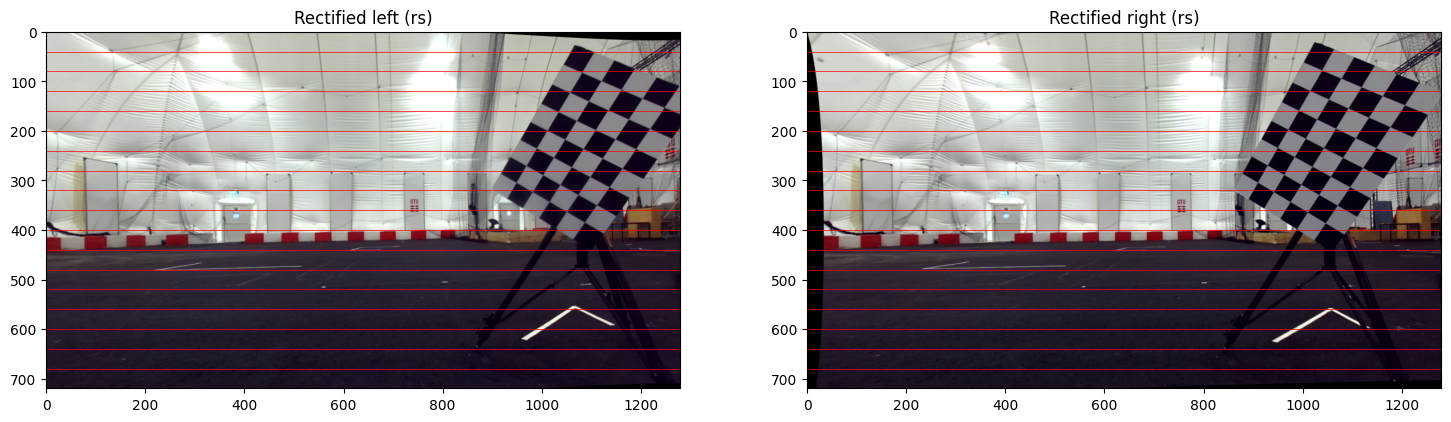

In [37]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 18))
ax[0].imshow(rect_l[..., [2, 1, 0]])
ax[0].set_title("Rectified left (rs)")
ax[1].imshow(rect_r[..., [2, 1, 0]])
ax[1].set_title("Rectified right (rs)")

for y in range(0, rect_l.shape[0], 40):
    ax[0].axhline(y, color="r", linewidth=0.5)
    ax[1].axhline(y, color="r", linewidth=0.5)

(719, 1279)
(719, 1279)


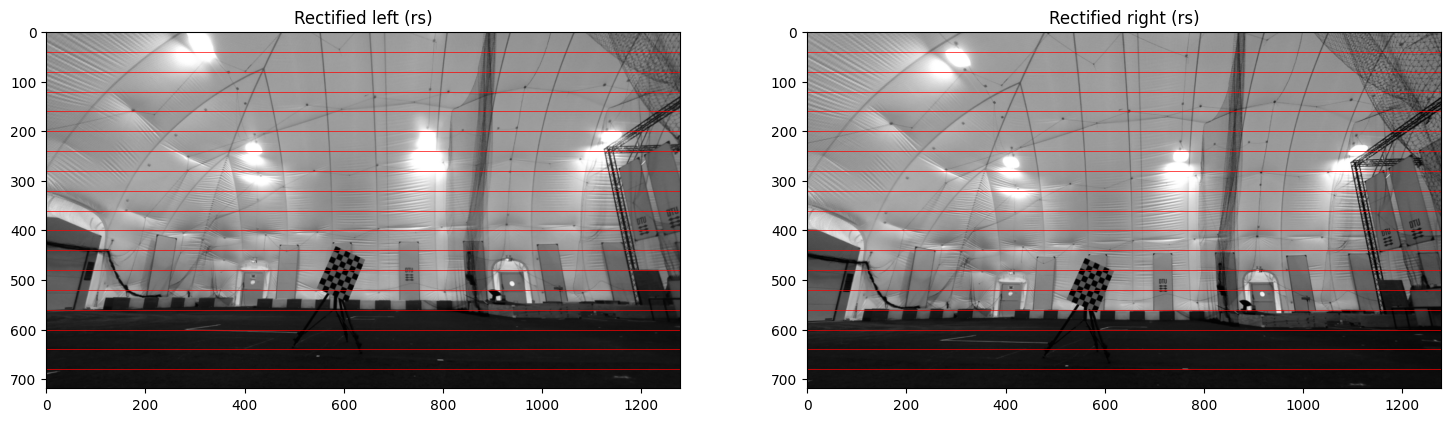

In [43]:
# sanity check

seq = 21
img_l = cv2.imread(left_img_calib[seq])
img_r = cv2.imread(right_img_calib[seq])
image_size = img.shape[::-1]  # (w, h)

img_l = cv2.cvtColor(img_l, cv2.COLOR_BGR2GRAY)
img_r = cv2.cvtColor(img_r, cv2.COLOR_BGR2GRAY)

# undistort
dst_left = cv2.undistort(img_l, mtx_left, dist_left, None, newcameramtx_left)
 
# crop the image
x, y, w, h = roi_left
dst_left = dst_left[y:y+h, x:x+w]
cv2.imwrite('calibresult_l.png', dst_left)
print(dst_left.shape)
# undistort
dst_right = cv2.undistort(img_r, mtx_right, dist_right, None, newcameramtx_right)
 
# crop the image
x, y, w, h = roi_right
dst_right = dst_right[y:y+h, x:x+w]
cv2.imwrite('calibresult_r.png', dst_right)
print(dst_right.shape)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 18))
ax[0].imshow(dst_left, cmap = 'gray')
ax[0].set_title("Rectified left (rs)")
ax[1].imshow(dst_right, cmap = 'gray')
ax[1].set_title("Rectified right (rs)")

for y in range(0, rect_l.shape[0], 40):
    ax[0].axhline(y, color="r", linewidth=0.5)
    ax[1].axhline(y, color="r", linewidth=0.5)

In [21]:
cv2.destroyAllWindows()

In [58]:
dir_list_l = [left_img_no_obs, left_img_obs, left_img_curve, left_img_circle]
dir_list_r = [right_img_no_obs, right_img_obs, right_img_curve, right_img_circle]

dir_lists = []
print([])

[]


In [44]:
np.savetxt('roi_left.csv', roi_left, delimiter = ', ')
np.savetxt('roi_right.csv', roi_right, delimiter = ', ')
np.savetxt('mtx_left.csv', mtx_left, delimiter = ', ')
np.savetxt('mtx_right.csv', mtx_right, delimiter = ', ')
np.savetxt('dist_right.csv', dist_right, delimiter = ', ')
np.savetxt('dist_left.csv', dist_left, delimiter = ', ')

## Undistort images

In [60]:
#mtx_left = np.loadtxt('mtx_left.csv', delimiter = ',', dtype = 'float32')
#dist_left = np.loadtxt('dist_left.csv', delimiter = ',', dtype = 'float32')

#mtx_right = np.loadtxt('mtx_right.csv', delimiter = ',', dtype = 'float32')
#dist_right = np.loadtxt('dist_right.csv', delimiter = ',', dtype = 'float32')

#dst_right = cv2.undistort(img_r, mtx_right, dist_right, None, newcameramtx_right)

dir_list_l = [left_img_no_obs, left_img_obs, left_img_curve, left_img_circle]
dir_list_r = [right_img_no_obs, right_img_obs, right_img_curve, right_img_circle]

dir_list_str = ['left_img_no_obs', 'left_img_obs', 'left_img_curve', 'left_img_circle','right_img_no_obs', 'right_img_obs', 'right_img_curve', 'right_img_circle']

for i, fold in enumerate(dir_list_l):
    for fname in fold:
        img_l = cv2.imread(fname)
        dst_left = cv2.undistort(img_l, mtx_left, dist_left, None, newcameramtx_left)
        cv2.imwrite('rectified/{}'.format(fname), dst_left)
    print('done with {}'.format(dir_list_str[i]))
print('done left')

for i, fold in enumerate(dir_list_r):
    for fname in fold:
        img_r = cv2.imread(fname)
        dst_right = cv2.undistort(img_r, mtx_right, dist_right, None, newcameramtx_right)
        cv2.imwrite('rectified/{}'.format(fname), dst_right)
    print('done with {}'.format(dir_list_str[i+3]))
print('done right')


done with left_img_no_obs
done with left_img_obs
done with left_img_curve
done with left_img_circle
done left
done with left_img_circle
done with right_img_no_obs
done with right_img_obs
done with right_img_curve
done right
